In [7]:
import os
import s3fs
import pandas as pd

fs = s3fs.S3FileSystem(
    client_kwargs={"endpoint_url": "https://" + os.environ["AWS_S3_ENDPOINT"]}
)

BUCKET = next(
    b for b in ["samuelbarre", "acharki-ensae"]
    if fs.exists(f"{b}/Projet-analyse-BPE/BPE25.parquet")
)

fs.ls(BUCKET)

['samuelbarre/Projet-analyse-BPE', 'samuelbarre/python_DS']

In [8]:
chemin_bpe = f"{BUCKET}/Projet-analyse-BPE/BPE25.parquet"

with fs.open(chemin_bpe, "rb") as f:
    bpe = pd.read_parquet(f)

bpe.shape

(2921770, 95)

In [9]:
bpe.columns

Index(['AN', 'APET', 'NOMRS', 'CNOMRS', 'NUMVOIE', 'INDREP', 'TYPVOIE',
       'LIBVOIE', 'CADR', 'CODPOS', 'DEPCOM', 'DEP', 'REG', 'LIBCOM', 'DOM',
       'SDOM', 'TYPEQU', 'SIRET', 'STATUT_DIFFUSION', 'CANTINE', 'INTERNAT',
       'RPI', 'EP', 'CL_PGE', 'SECT', 'SECTEUR', 'ACCES_AIRE_PRATIQUE',
       'ACCES_LIBRE', 'ACCES_SANITAIRE', 'ACCES_VESTIAIRE',
       'CAPACITE_D_ACCUEIL', 'PRES_DOUCHE', 'PRES_SANITAIRE', 'SAISONNIER',
       'COUVERT', 'ECLAIRE', 'CATEGORIE', 'MULTIPLEXE', 'STRUCTURE_EXERCICE',
       'SPECIALITE', 'ACCUEIL', 'ITINERANCE', 'MODE_GESTION', 'SSTYPHEB',
       'TYPE', 'TYPERESTO', 'IMPLANTATION_STATION', 'GPL', 'CAPACITE',
       'INDIC_CAPA', 'NBEQUIDENT', 'INDIC_NBEQUIDENT', 'NBSALLES',
       'INDIC_NBSALLES', 'NBLIEUX', 'INDIC_NBLIEUX', 'NB_PDC', 'INDIC_NB_PDC',
       'NB_PDC_PA', 'INDIC_NB_PDC_PA', 'NB_PDC_ACCELEREE',
       'INDIC_NB_PDC_ACCELEREE', 'NB_PDC_LENTE', 'INDIC_NB_PDC_LENTE',
       'NB_PDC_RAPIDE', 'INDIC_NB_PDC_RAPIDE', 'NB_PDC_ULTRARAPIDE'

In [10]:
colonnes = [
    "DOM", "SDOM", "TYPEQU", "SIRET", "NOMRS", "APET",
    "DEPCOM", "DEP", "REG", "LIBCOM",
    "LAMBERT_X", "LAMBERT_Y", "EPSG", "LONGITUDE", "LATITUDE",
    "QUALITE_XY", "QUALITE_GEOLOC",
    "DENS3", "DENS7",
]

bde = bpe[colonnes].copy()

In [11]:
bpe = bpe.loc[bpe["SDOM"].isin(["B1", "B2"]), :].copy()

In [12]:
bpe = bpe[bpe["TYPEQU"] != "B103"].copy()

In [13]:
bpe["TYPEQU"].value_counts().sort_index()

TYPEQU
B104     2256
B105    12929
B201     5617
B202    30104
B204    17378
B205     1726
B206     2346
B207    50122
B208     6627
B209     8537
B210    13669
Name: count, dtype: int64

In [14]:
import pandas as pd
import geopandas as gpd

colonnes = [
    "DOM", "SDOM", "TYPEQU", "SIRET", "NOMRS", "APET",
    "DEPCOM", "DEP", "REG", "LIBCOM",
    "LAMBERT_X", "LAMBERT_Y", "EPSG", "LONGITUDE", "LATITUDE",
    "QUALITE_XY", "QUALITE_GEOLOC",
    "DENS3", "DENS7",
]

bpe_alim = bpe[colonnes].copy()
print("Lignes au départ :", len(bpe_alim))


Lignes au départ : 151311


In [15]:

for col in ["DOM", "SDOM", "TYPEQU", "SIRET", "DEPCOM", "DEP", "REG", "APET"]:
    bpe_alim[col] = bpe_alim[col].astype("string")


for col in ["LAMBERT_X", "LAMBERT_Y", "LONGITUDE", "LATITUDE"]:
    bpe_alim[col] = pd.to_numeric(bpe_alim[col], errors="coerce")

bpe_alim.dtypes

DOM                string
SDOM               string
TYPEQU             string
SIRET              string
NOMRS                 str
APET               string
DEPCOM             string
DEP                string
REG                string
LIBCOM                str
LAMBERT_X         float64
LAMBERT_Y         float64
EPSG                  str
LONGITUDE         float64
LATITUDE          float64
QUALITE_XY            str
QUALITE_GEOLOC        str
DENS3                 str
DENS7                 str
dtype: object

In [16]:
bpe_alim.isna().sum()

DOM                  0
SDOM                 0
TYPEQU               0
SIRET                0
NOMRS                0
APET                 0
DEPCOM               0
DEP                  0
REG                  0
LIBCOM               0
LAMBERT_X         4756
LAMBERT_Y         4756
EPSG                 0
LONGITUDE         4756
LATITUDE          4756
QUALITE_XY           0
QUALITE_GEOLOC       0
DENS3                0
DENS7                0
dtype: int64

In [17]:
sans_coord = bpe_alim["LONGITUDE"].isna() | bpe_alim["LATITUDE"].isna()
bpe_alim.loc[sans_coord, "DEP"].value_counts()

DEP
976    1784
75      119
59      106
33       77
34       75
       ... 
05        8
10        7
48        7
90        6
15        5
Name: count, Length: 101, dtype: int64[pyarrow]

In [18]:
(bpe_alim["DEP"] == "75").sum()

8583

In [19]:
# Ajout du code postal à bpe_alim
bpe_alim["CODPOS"] = bpe.loc[bpe_alim.index, "CODPOS"].astype("string")

# Tableau par code postal parisien
paris = bpe_alim[bpe_alim["DEP"] == "75"].copy()
paris["sans_coord"] = paris["LONGITUDE"].isna()

impact_cp = (
    paris.groupby("CODPOS")
    .agg(nb_commerces=("sans_coord", "size"), nb_sans_coord=("sans_coord", "sum"))
    .assign(part_sans_coord=lambda d: (d["nb_sans_coord"] / d["nb_commerces"]).round(3))
    .sort_index()
)

impact_cp

,nb_commerces,nb_sans_coord,part_sans_coord
CODPOS,,,
,119,119,1.0
75001,169,0,0.0
75002,172,0,0.0
75003,186,0,0.0
75004,178,0,0.0
75005,285,0,0.0
75006,239,0,0.0
75007,266,0,0.0
75008,357,0,0.0


In [20]:
n_avant = len(bpe_alim)
bpe_alim = bpe_alim.dropna(subset=["LONGITUDE", "LATITUDE"]).copy()

print("Commerces sans coordonnées supprimés :", n_avant - len(bpe_alim))
print("Commerces restants :", len(bpe_alim))

Commerces sans coordonnées supprimés : 4756
Commerces restants : 146555


In [21]:
bpe_alim = bpe_alim[bpe_alim["TYPEQU"] != "B103"].copy()

In [22]:
# DROM : systèmes de coordonnées différents, on se limite à la métropole
DROM = ["971", "972", "973", "974", "976"]
# Absents de DVF (Alsace-Moselle) : inutiles pour le croisement
ABSENTS_DVF = ["57", "67", "68"]

n_avant = len(bpe_alim)
bpe_alim = bpe_alim[~bpe_alim["DEP"].isin(DROM + ABSENTS_DVF)].copy()
print("Lignes retirées (DROM + Alsace-Moselle) :", n_avant - len(bpe_alim))
print("Lignes restantes :", len(bpe_alim))

Lignes retirées (DROM + Alsace-Moselle) : 10968
Lignes restantes : 135587


In [23]:
import geopandas as gpd

bpe_geo = gpd.GeoDataFrame(
    bpe_alim,
    geometry=gpd.points_from_xy(bpe_alim["LONGITUDE"], bpe_alim["LATITUDE"]),
    crs="EPSG:4326",
)

bpe_geo = bpe_geo.to_crs("EPSG:2154")

bpe_geo.head()

,DOM,SDOM,TYPEQU,SIRET,NOMRS,APET,DEPCOM,DEP,REG,LIBCOM,...,LAMBERT_Y,EPSG,LONGITUDE,LATITUDE,QUALITE_XY,QUALITE_GEOLOC,DENS3,DENS7,CODPOS,geometry
94706,B,B1,B104,55208329701265,"MONOPRIX EXPLOITATION, PAR ABREVIATION MPX",4711F,75101,75,11,PARIS 1ER ARRONDISSEMENT,...,6863148.0,2154,2.33386,48.86650,B,11,1,1,75001,POINT (651132.682 6863147.252)
94707,B,B1,B104,53775858300059,SAMARITAINE SAS,4719A,75101,75,11,PARIS 1ER ARRONDISSEMENT,...,6862376.0,2154,2.34303,48.85961,B,11,1,1,75001,POINT (651798.993 6862375.504)
94708,B,B1,B105,82193739800021,SUPERMARCHE SAINT HONORE,4711D,75101,75,11,PARIS 1ER ARRONDISSEMENT,...,6863134.0,2154,2.33187,48.86637,B,11,1,1,75001,POINT (650986.578 6863134.03)
94709,B,B1,B105,80379904800050,MINI LP 1,4711D,75101,75,11,PARIS 1ER ARRONDISSEMENT,...,6862632.0,2154,2.33955,48.86189,B,11,1,1,75001,POINT (651545.797 6862631.151)
94710,B,B1,B105,83815680000016,METATRON313,4711D,75101,75,11,PARIS 1ER ARRONDISSEMENT,...,6862854.0,2154,2.34548,48.86392,B,11,1,1,75001,POINT (651982.715 6862853.248)


In [24]:
print(bpe_geo["DEP"].isin(["971", "972", "973", "974", "976", "57", "67", "68"]).sum())  # doit valoir 0
print(bpe_geo["TYPEQU"].value_counts().sort_index())

0
TYPEQU
B104     2081
B105    12106
B201     5114
B202    25461
B204    16267
B205     1594
B206     2183
B207    44779
B208     5807
B209     7859
B210    12336
Name: count, dtype: int64[pyarrow]


In [25]:
print(bpe_geo["DEP"].isin(["971", "972", "973", "974", "976", "57", "67", "68"]).sum())  # doit valoir 0
print(bpe_geo["TYPEQU"].value_counts().sort_index())

0
TYPEQU
B104     2081
B105    12106
B201     5114
B202    25461
B204    16267
B205     1594
B206     2183
B207    44779
B208     5807
B209     7859
B210    12336
Name: count, dtype: int64[pyarrow]


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

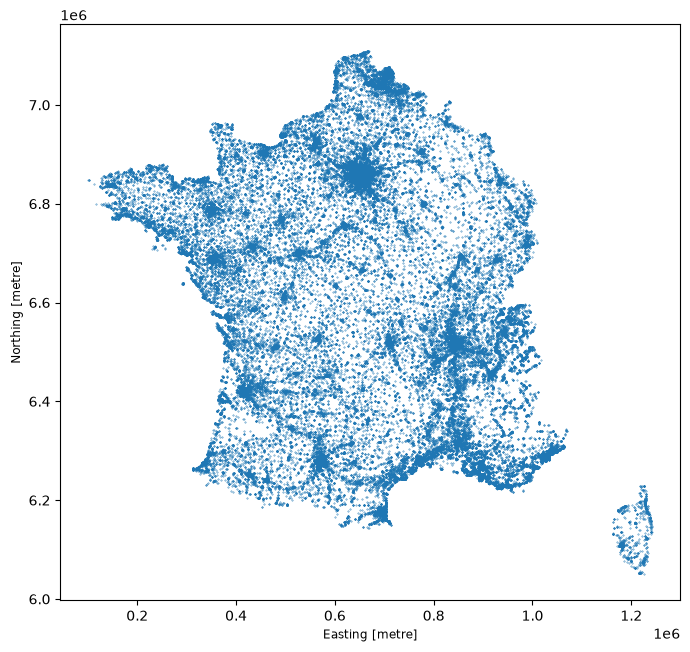

In [26]:
bpe_geo.plot(markersize=0.1, figsize=(8, 8))

In [27]:
import os
import s3fs

# Désactive les sommes de contrôle automatiques, mal gérées par le stockage du Datalab
os.environ["AWS_REQUEST_CHECKSUM_CALCULATION"] = "when_required"
os.environ["AWS_RESPONSE_CHECKSUM_VALIDATION"] = "when_required"

fs = s3fs.S3FileSystem(
    client_kwargs={"endpoint_url": "https://" + os.environ["AWS_S3_ENDPOINT"]},
    skip_instance_cache=True,
)

In [29]:
chemin_sortie = f"{BUCKET}/Projet-analyse-BPE/processed/bpe_alim_2025.parquet"

with fs.open(chemin_sortie, "wb") as f:
    bpe_geo.to_parquet(f)

fs.ls(f"{BUCKET}/Projet-analyse-BPE/processed")

['samuelbarre/Projet-analyse-BPE/processed/bpe_alim_2025.parquet']

In [30]:
bpe_geo.to_parquet("/home/onyxia/work/bpe_alim_2025.parquet")
